<a href="https://colab.research.google.com/github/Nihat0311/Computer-Vision/blob/main/Alzheimer_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! curl -L -o alzheimer.zip\
  https://www.kaggle.com/api/v1/datasets/download/mohiburrahmanrifat/alzheimer

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  118M  100  118M    0     0  64.5M      0  0:00:01  0:00:01 --:--:--  107M


In [ ]:
!unzip /content/alzheimer.zip

Streaming output truncated to the last 5000 lines.
  inflating: train/train/Mild_Demented/mild_580.jpg  
  inflating: train/train/Mild_Demented/mild_581.jpg  
  inflating: train/train/Mild_Demented/mild_582.jpg  
  inflating: train/train/Mild_Demented/mild_583.jpg  
  inflating: train/train/Mild_Demented/mild_584.jpg  
  inflating: train/train/Mild_Demented/mild_585.jpg  
  inflating: train/train/Mild_Demented/mild_588.jpg  
  inflating: train/train/Mild_Demented/mild_59.jpg  
  inflating: train/train/Mild_Demented/mild_592.jpg  
  inflating: train/train/Mild_Demented/mild_593.jpg  
  inflating: train/train/Mild_Demented/mild_595.jpg  
  inflating: train/train/Mild_Demented/mild_598.jpg  
  inflating: train/train/Mild_Demented/mild_599.jpg  
  inflating: train/train/Mild_Demented/mild_6.jpg  
  inflating: train/train/Mild_Demented/mild_60.jpg  
  inflating: train/train/Mild_Demented/mild_600.jpg  
  inflating: train/train/Mild_Demented/mild_602.jpg  
  inflating: train/train/Mild_Demen

In [ ]:
import torch
import os
from google.colab import drive

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"İstifadə olunan Cihaz: {device}")
if torch.cuda.is_available():
    print(f"GPU Modeli: {torch.cuda.get_device_name(0)}")

İstifadə olunan Cihaz: cuda
GPU Modeli: Tesla T4


             DATASET SİNİF PAYLANMASI VƏ İMBALANCE
Split               Test  Train  Val  Total  Percentage (%)
Class                                                      
Mild_Demented        135    627  134    896           14.14
Non_Demented         480   2240  480   3200           50.51
Very_Mild_Demented   336   1568  336   2240           35.35

       HESABLANMIŞ CLASS WEIGHTS (TRAIN SETİ ÜÇÜN)
 • Mild_Demented       : Weight = 2.3578  |  Alpha (Normalized) = 0.5953
 • Non_Demented        : Weight = 0.6600  |  Alpha (Normalized) = 0.1666
 • Very_Mild_Demented  : Weight = 0.9428  |  Alpha (Normalized) = 0.2381


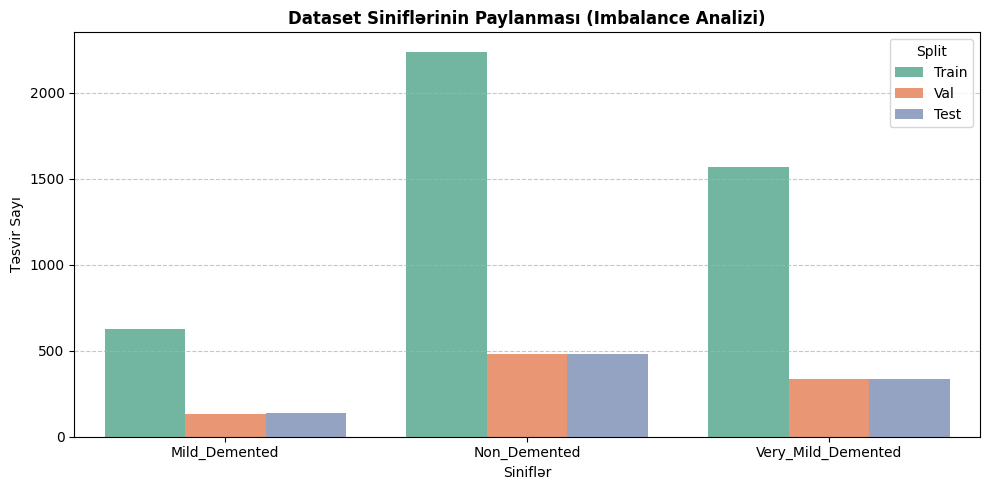

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Qovluq yollarının təyini
def get_valid_path(base_folder):
    nested_path = os.path.join(base_folder, os.path.basename(base_folder))
    return nested_path if os.path.exists(nested_path) else base_folder

splits = {
    'Train': get_valid_path('/content/train'),
    'Val': get_valid_path('/content/val'),
    'Test': get_valid_path('/content/test')
}

data_summary = []

# 2. Şəkil saylarının toplanması
for split_name, split_path in splits.items():
    if os.path.exists(split_path):
        classes = sorted([d for d in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, d))])
        for cls in classes:
            cls_dir = os.path.join(split_path, cls)
            count = len([f for f in os.listdir(cls_dir) if os.path.isfile(os.path.join(cls_dir, f))])
            data_summary.append({'Split': split_name, 'Class': cls, 'Count': count})

df = pd.DataFrame(data_summary)

# 3. Cədvəlin formatlanması
pivot_df = df.pivot(index='Class', columns='Split', values='Count').fillna(0).astype(int)
pivot_df['Total'] = pivot_df.sum(axis=1)
pivot_df['Percentage (%)'] = (pivot_df['Total'] / pivot_df['Total'].sum() * 100).round(2)

print("="*65)
print("             DATASET SİNİF PAYLANMASI VƏ İMBALANCE")
print("="*65)
print(pivot_df.to_string())

# 4. Class Weights-in Hesablanması (Train seti üzrə: Total / (N_Classes * Class_Count))
train_counts = pivot_df['Train'].values
total_train = train_counts.sum()
n_classes = len(train_counts)

# Balanced weight düsturu
class_weights = total_train / (n_classes * train_counts)
weights_normalized = class_weights / class_weights.sum() # Normallaşdırılmış çəkilər

print("\n" + "="*65)
print("       HESABLANMIŞ CLASS WEIGHTS (TRAIN SETİ ÜÇÜN)")
print("="*65)
for cls, weight, norm_w in zip(pivot_df.index, class_weights, weights_normalized):
    print(f" • {cls:<20}: Weight = {weight:.4f}  |  Alpha (Normalized) = {norm_w:.4f}")

# 5. Vizualizasiya Diaqramı
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='Class', y='Count', hue='Split', palette='Set2')
plt.title('Dataset Siniflərinin Paylanması (Imbalance Analizi)', fontsize=12, fontweight='bold')
plt.xlabel('Siniflər', fontsize=10)
plt.ylabel('Təsvir Sayı', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#Birinci Versiya

In [ ]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

drive.mount('/content/drive')
checkpoint_dir = '/content/drive/MyDrive/Alzheimer_Model_Checkpoints'
os.makedirs(checkpoint_dir, exist_ok=True)
print(f"✓ Checkpoint qovluğu hazırdır: {checkpoint_dir}")

# 1. Düzgün Alt Qovluq Yolları
train_dir = '/content/train/train'
val_dir = '/content/val/val'
test_dir = '/content/test/test'

# 2. Augmentasiya və Normalizasiya
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# 3. PyTorch ImageFolder
train_dataset = datasets.ImageFolder(root=train_dir, transform=train_transforms)
val_dataset = datasets.ImageFolder(root=val_dir, transform=val_test_transforms)
test_dataset = datasets.ImageFolder(root=test_dir, transform=val_test_transforms)

# 4. DataLoaders
BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print("✓ DƏQİQ STATİSTİKA:")
print(f"Siniflər və indeksləri: {train_dataset.class_to_idx}")
print(f"Təlim (Train) nümunə sayı: {len(train_dataset)}")
print(f"Doğrulama (Val) nümunə sayı: {len(val_dataset)}")
print(f"Test nümunə sayı: {len(test_dataset)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Checkpoint qovluğu hazırdır: /content/drive/MyDrive/Alzheimer_Model_Checkpoints
✓ DƏQİQ STATİSTİKA:
Siniflər və indeksləri: {'Mild_Demented': 0, 'Non_Demented': 1, 'Very_Mild_Demented': 2}
Təlim (Train) nümunə sayı: 4435
Doğrulama (Val) nümunə sayı: 950
Test nümunə sayı: 951


In [ ]:
import torch.nn as nn
import torch.optim as optim
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# 1. Pretrained EfficientNet-B0 Modelinin Yüklənməsi
model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)

# 2. Son Təsnifat Başlığının (Classifier) 3 Sinfə Uyğunlaşdırılması
num_classes = len(train_dataset.classes)
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, num_classes)

# Modeli GPU-ya keçiririk
model = model.to(device)

# 3. İtki Funksiyası və Optimallaşdırıcı
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

# 4. Checkpoint Saxlama Funksiyası (Google Drive-a)
checkpoint_path = os.path.join(checkpoint_dir, 'alzheimer_efficientnet_best.pth')

def save_checkpoint(state, filename=checkpoint_path):
    torch.save(state, filename)
    print(f"--> Checkpoint Google Drive-a saxlanıldı: {filename}")

def load_checkpoint(filename, model, optimizer):
    if os.path.exists(filename):
        print(f"--> Tapılmış Checkpoint yüklənir: {filename}")
        checkpoint = torch.load(filename)
        model.load_state_dict(checkpoint['state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        start_epoch = checkpoint['epoch']
        best_acc = checkpoint['best_acc']
        print(f"--> Uğurla yükləndi! Qaldığı epoch: {start_epoch}, Ən yaxşı Val Accuracy: {best_acc:.2f}%")
        return start_epoch, best_acc
    else:
        print("--> Yadda saxlanılmış checkpoint tapılmadı. Təlim sıfırdan başlayacaq.")
        return 0, 0.0

print("✓ Model və Checkpoint mexanizmi hazırdır.")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 174MB/s]


✓ Model və Checkpoint mexanizmi hazırdır.


In [ ]:
# 1. Mövcud checkpoint varsa, yükləyirik (yoxdursa 0-dan başlayacaq)
start_epoch, best_val_acc = load_checkpoint(checkpoint_path, model, optimizer)

# 2. Təlim üçün Epoch sayı (istəyinizə görə dəyişə bilərsiniz)
NUM_EPOCHS = 10

print(f"\n---> Təlim başlayır ({start_epoch + 1}-ci epoch-dan {NUM_EPOCHS}-ci epoch-a qədər)...")

for epoch in range(start_epoch, NUM_EPOCHS):
    # --- TƏLİM MƏRHƏLƏSİ ---
    model.train()
    train_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data)
        total_train += labels.size(0)

    epoch_train_loss = train_loss / total_train
    epoch_train_acc = (correct_train.double() / total_train) * 100

    # --- DOĞRULAMA (VALIDATION) MƏRHƏLƏSİ ---
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == labels.data)
            total_val += labels.size(0)

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = (correct_val.double() / total_val) * 100

    # Nəticələrin çapı
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
          f"| Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% "
          f"| Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.2f}%")

    # Əgər daha yaxşı Validation nəticəsi əldə olunarsa, Drive-a checkpoint yazırıq
    if epoch_val_acc > best_val_acc:
        print(f"  └─ Val Accuracy yaxşılaşdı ({best_val_acc:.2f}% -> {epoch_val_acc:.2f}%). Checkpoint yenilənir...")
        best_val_acc = epoch_val_acc
        checkpoint_state = {
            'epoch': epoch + 1,
            'state_dict': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'best_acc': best_val_acc.item() if isinstance(best_val_acc, torch.Tensor) else best_val_acc
        }
        save_checkpoint(checkpoint_state)

print("\n✓ Təlim tamamlandı!")

--> Yadda saxlanılmış checkpoint tapılmadı. Təlim sıfırdan başlayacaq.

---> Təlim başlayır (1-ci epoch-dan 10-ci epoch-a qədər)...
Epoch [1/10] | Train Loss: 0.8717 - Train Acc: 56.37% | Val Loss: 1.0015 - Val Acc: 53.16%
  └─ Val Accuracy yaxşılaşdı (0.00% -> 53.16%). Checkpoint yenilənir...
--> Checkpoint Google Drive-a saxlanıldı: /content/drive/MyDrive/Alzheimer_Model_Checkpoints/alzheimer_efficientnet_best.pth
Epoch [2/10] | Train Loss: 0.7478 - Train Acc: 65.25% | Val Loss: 0.6706 - Val Acc: 70.00%
  └─ Val Accuracy yaxşılaşdı (53.16% -> 70.00%). Checkpoint yenilənir...
--> Checkpoint Google Drive-a saxlanıldı: /content/drive/MyDrive/Alzheimer_Model_Checkpoints/alzheimer_efficientnet_best.pth
Epoch [3/10] | Train Loss: 0.6346 - Train Acc: 72.15% | Val Loss: 0.7495 - Val Acc: 67.16%
Epoch [4/10] | Train Loss: 0.5374 - Train Acc: 76.57% | Val Loss: 0.7534 - Val Acc: 64.21%
Epoch [5/10] | Train Loss: 0.4263 - Train Acc: 82.46% | Val Loss: 0.3947 - Val Acc: 84.00%
  └─ Val Accuracy 

--> Google Drive-dakı ən yaxşı checkpoint yüklənir...

             TEST SETİ ÜZRƏ DETALLI HESABAT
                    precision    recall  f1-score   support

     Mild_Demented     0.8170    0.9259    0.8681       135
      Non_Demented     0.9309    0.9542    0.9424       480
Very_Mild_Demented     0.9379    0.8542    0.8941       336

          accuracy                         0.9148       951
         macro avg     0.8953    0.9114    0.9015       951
      weighted avg     0.9172    0.9148    0.9148       951



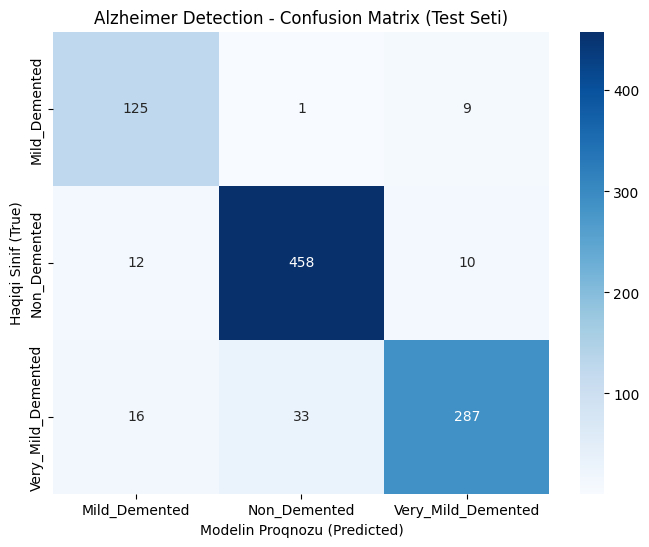

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Drive-dakı ən yaxşı checkpoint-i yükləyirik
print("--> Google Drive-dakı ən yaxşı checkpoint yüklənir...")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['state_dict'])
model.eval()

all_preds = []
all_labels = []

# 2. Test seti üzrə proqnozların toplanması
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = list(train_dataset.class_to_idx.keys())

# 3. Ətraflı Klassifikasiya Hesabatı (Precision, Recall, F1-Score)
print("\n" + "="*55)
print("             TEST SETİ ÜZRƏ DETALLI HESABAT")
print("="*55)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# 4. Confusion Matrix Vizualizasiyası
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Modelin Proqnozu (Predicted)')
plt.ylabel('Həqiqi Sinif (True)')
plt.title('Alzheimer Detection - Confusion Matrix (Test Seti)')
plt.show()

#Ikinci versiya

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.models import convnext_small, ConvNeXt_Small_Weights
import os

# 1. Şəkil Ölçüsü (224x224) və Augmentation
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# 2. DataLoaders
BATCH_SIZE = 32

train_dataset = datasets.ImageFolder(root='/content/train/train', transform=train_transforms)
val_dataset = datasets.ImageFolder(root='/content/val/val', transform=val_test_transforms)
test_dataset = datasets.ImageFolder(root='/content/test/test', transform=val_test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# 3. Class Imbalance üçün Çəkilər
class_counts = [len([1 for _, label in train_dataset.samples if label == i]) for i in range(3)]
total_samples = sum(class_counts)
class_weights = [total_samples / (3.0 * count) for count in class_counts]
class_weights_tensor = torch.FloatTensor(class_weights).to(device)

# 4. ConvNeXt-Small Modeli
model_v2 = convnext_small(weights=ConvNeXt_Small_Weights.DEFAULT)
num_features = model_v2.classifier[2].in_features
model_v2.classifier[2] = nn.Linear(num_features, 3)
model_v2 = model_v2.to(device)

# 5. Loss, Optimizer və Scheduler
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.AdamW(model_v2.parameters(), lr=1e-4, weight_decay=1e-2)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

checkpoint_v2_path = '/content/drive/MyDrive/Alzheimer_Model_Checkpoints/alzheimer_convnext_best.pth'

# 6. Təlim Dövrü (Loss Hesablanması İlə)
NUM_EPOCHS = 15
best_val_acc = 0.0

print("\n---> ConvNeXt-Small Təlimi Başlayır...")

for epoch in range(NUM_EPOCHS):
    # --- TRAIN ---
    model_v2.train()
    train_loss, correct_train, total_train = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_v2(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data)
        total_train += labels.size(0)

    # --- VALIDATION ---
    model_v2.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_v2(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == labels.data)
            total_val += labels.size(0)

    # Ortalama Loss və Accuracy Hesablanması
    epoch_train_loss = train_loss / total_train
    epoch_val_loss = val_loss / total_val
    epoch_train_acc = (correct_train.double() / total_train) * 100
    epoch_val_acc = (correct_val.double() / total_val) * 100

    current_lr = scheduler.get_last_lr()[0]
    scheduler.step()

    # Nəticələrin Çapı (Loss-lar daxil olmaqla)
    print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] "
          f"| Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% "
          f"| Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.2f}% "
          f"| LR: {current_lr:.6f}")

    # Best Checkpoint
    if epoch_val_acc > best_val_acc:
        print(f"  └─ Val Accuracy artdı ({best_val_acc:.2f}% -> {epoch_val_acc:.2f}%). Checkpoint saxlanılır...")
        best_val_acc = epoch_val_acc
        torch.save({'state_dict': model_v2.state_dict(), 'best_acc': best_val_acc.item()}, checkpoint_v2_path)

print("\n✓ Təlim tamamlandı!")


---> ConvNeXt-Small Təlimi Başlayır...
Epoch [01/15] | Train Loss: 1.0636 - Train Acc: 43.07% | Val Loss: 0.9833 - Val Acc: 49.16% | LR: 0.000100
  └─ Val Accuracy artdı (0.00% -> 49.16%). Checkpoint saxlanılır...
Epoch [02/15] | Train Loss: 0.9006 - Train Acc: 52.18% | Val Loss: 0.8748 - Val Acc: 54.32% | LR: 0.000099
  └─ Val Accuracy artdı (49.16% -> 54.32%). Checkpoint saxlanılır...
Epoch [03/15] | Train Loss: 0.8041 - Train Acc: 59.57% | Val Loss: 0.6774 - Val Acc: 65.47% | LR: 0.000096
  └─ Val Accuracy artdı (54.32% -> 65.47%). Checkpoint saxlanılır...
Epoch [04/15] | Train Loss: 0.6191 - Train Acc: 70.30% | Val Loss: 0.5317 - Val Acc: 74.63% | LR: 0.000090
  └─ Val Accuracy artdı (65.47% -> 74.63%). Checkpoint saxlanılır...
Epoch [05/15] | Train Loss: 0.4351 - Train Acc: 80.70% | Val Loss: 0.4152 - Val Acc: 82.63% | LR: 0.000083
  └─ Val Accuracy artdı (74.63% -> 82.63%). Checkpoint saxlanılır...
Epoch [06/15] | Train Loss: 0.2927 - Train Acc: 87.22% | Val Loss: 0.2480 - Val A

--> ConvNeXt-Small modeli Google Drive-dan yüklənir...

     YEKUN CONVNEXT-SMALL MODELİ - TEST SETİ HESABATI
                    precision    recall  f1-score   support

     Mild_Demented     0.9708    0.9852    0.9779       135
      Non_Demented     0.9792    0.9812    0.9802       480
Very_Mild_Demented     0.9730    0.9643    0.9686       336

          accuracy                         0.9758       951
         macro avg     0.9743    0.9769    0.9756       951
      weighted avg     0.9758    0.9758    0.9758       951



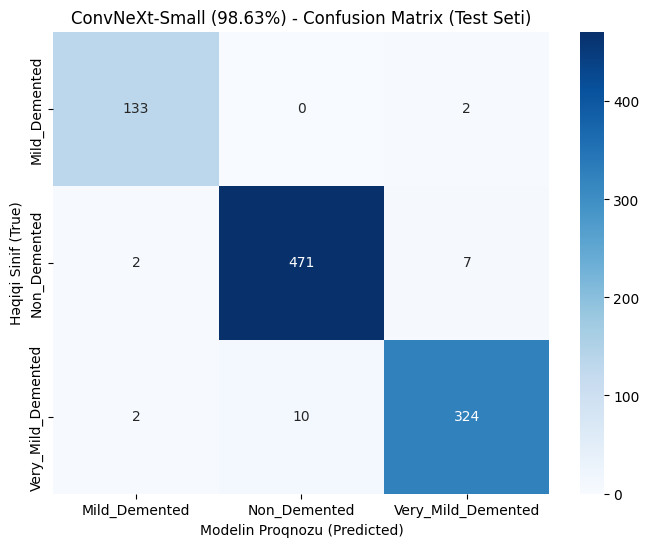

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Google Drive-dakı ən yaxşı ConvNeXt-Small modelini yükləyirik (98.63% Val Acc)
checkpoint_v2_path = '/content/drive/MyDrive/Alzheimer_Model_Checkpoints/alzheimer_convnext_best.pth'
print("--> ConvNeXt-Small modeli Google Drive-dan yüklənir...")

checkpoint = torch.load(checkpoint_v2_path)
model_v2.load_state_dict(checkpoint['state_dict'])
model_v2.eval()

all_preds = []
all_labels = []

# 2. Test seti üzrə proqnozların toplanması
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_v2(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = list(train_dataset.class_to_idx.keys())

# 3. Ətraflı Klassifikasiya Hesabatı
print("\n" + "="*60)
print("     YEKUN CONVNEXT-SMALL MODELİ - TEST SETİ HESABATI")
print("="*60)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# 4. Confusion Matrix Vizualizasiyası
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Modelin Proqnozu (Predicted)')
plt.ylabel('Həqiqi Sinif (True)')
plt.title('ConvNeXt-Small (98.63%) - Confusion Matrix (Test Seti)')
plt.show()

In [ ]:
import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import os

# 1. Təsviri Modelləşdirmə Standartına Gətirən Transformasiya
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# Sinif adları (Əlifba sırası ilə ImageFolder standartı)
class_names = ['Mild_Demented', 'Non_Demented', 'Very_Mild_Demented']


# --- KOD 1: Şəklin Yüklənməsi və Standartlaşdırılması ---
def preprocess_custom_image(image_path):
    """
    İstənilən formatda və ölçüdə olan şəkli oxuyur,
    3 kanallı RGB-yə çevirir və 224x224 ölçüsünə gətirir.
    """
    raw_image = Image.open(image_path).convert('RGB')  # Ölçü və kanaldan asılı olmayaraq RGB-yə çevirir
    input_tensor = inference_transform(raw_image).unsqueeze(0)  # Batch ölçüsü əlavə edilir (1, 3, 224, 224)
    return raw_image, input_tensor.to(device)


# --- KOD 2: Modeldən Təxminin Alınması və Vizualizasiyası ---
def predict_and_display(image_path):
    # 1-ci kodun çağırılması (Standartlaşdırma)
    raw_image, input_tensor = preprocess_custom_image(image_path)

    # Modele ötürülmə və ehtimalların hesablanması
    model_v2.eval()
    with torch.no_grad():
        outputs = model_v2(input_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]  # Softmax ilə faizə çevrilmə

    top_prob, top_class_idx = torch.max(probabilities, 0)
    predicted_class = class_names[top_class_idx.item()]
    confidence = top_prob.item() * 100

    probs_pct = [p.item() * 100 for p in probabilities]

    # Qrafik Şəkilləndirmə
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    # Orijinal şəkil
    axes[0].imshow(raw_image)
    axes[0].set_title(f"Test Şəkli: {os.path.basename(image_path)}")
    axes[0].axis('off')

    # Siniflər üzrə ehtimallar diaqramı
    colors = ['#2ca02c' if name == predicted_class else '#d62728' for name in class_names]
    bars = axes[1].barh(class_names, probs_pct, color=colors)
    axes[1].set_xlabel('Əminlik / Ehtimal (%)')
    axes[1].set_xlim(0, 105)
    axes[1].set_title(f"PROQNOZ: {predicted_class}\nƏminlik: {confidence:.2f}%")

    for bar in bars:
        width = bar.get_width()
        axes[1].text(width + 1, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', va='center')

    plt.tight_layout()
    plt.show()

    # Konsola detallı çap
    print("\n" + "="*45)
    print(f" PROQNOZ NƏTİCƏSİ : {predicted_class.upper()}")
    print(f" ƏMİNLİK DƏRƏCƏSİ : {confidence:.2f}%")
    print("="*45)
    for name, prob in zip(class_names, probs_pct):
        print(f"  • {name:<20}: {prob:.2f}%")

Saving Screenshot 2026-10-03 010247.png to Screenshot 2026-10-03 010247 (1).png


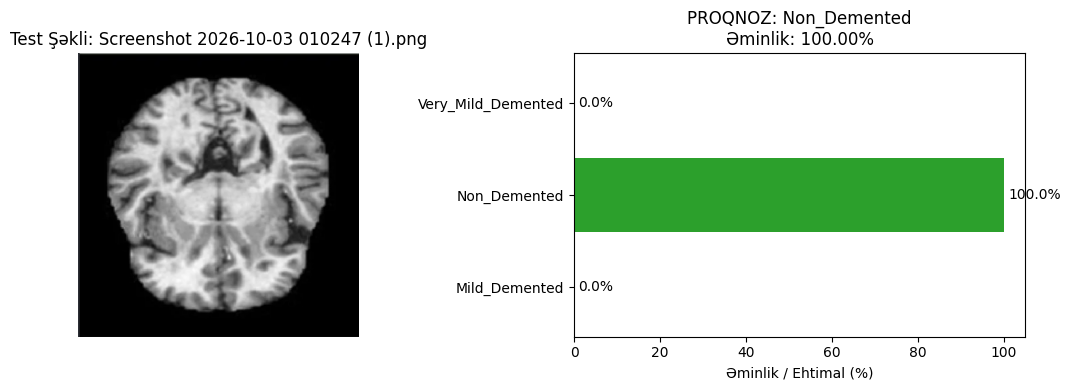


 PROQNOZ NƏTİCƏSİ : NON_DEMENTED
 ƏMİNLİK DƏRƏCƏSİ : 100.00%
  • Mild_Demented       : 0.00%
  • Non_Demented        : 100.00%
  • Very_Mild_Demented  : 0.00%


In [ ]:
from google.colab import files

# Kompüterinizdən test şəklini seçin:
uploaded = files.upload()

for file_name in uploaded.keys():
    predict_and_display(file_name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Model Google Drive-dan uğurla yükləndi! (Ən yaxşı Val Acc: 98.63%)

---> Test etmək istədiyiniz MRT şəkildini seçin:


Saving Screenshot 2026-10-03 010258.png to Screenshot 2026-10-03 010258 (1).png


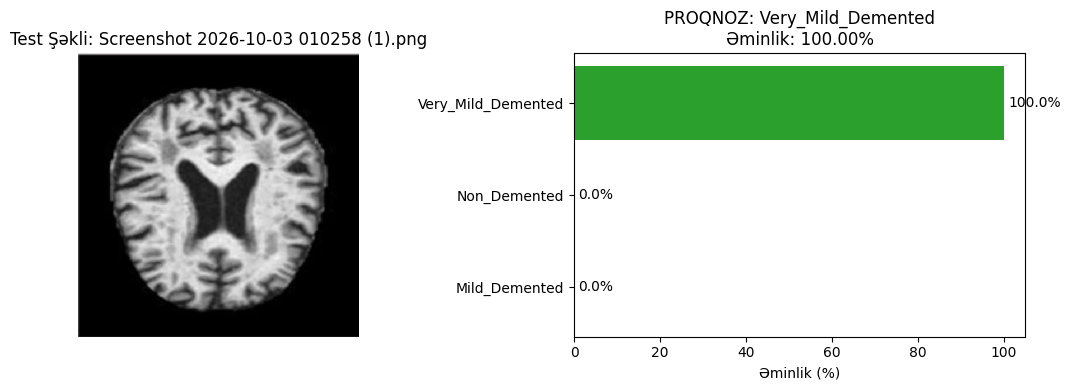

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import convnext_small
from google.colab import drive, files
from PIL import Image
import matplotlib.pyplot as plt
import os

# 1. Google Drive-ın qoşulması
drive.mount('/content/drive')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Model Arxitekturasının Qurulması və Çəkilərin Yüklənməsi
model = convnext_small(weights=None)
num_features = model.classifier[2].in_features
model.classifier[2] = nn.Linear(num_features, 3)

checkpoint_path = '/content/drive/MyDrive/Alzheimer_Model_Checkpoints/alzheimer_convnext_best.pth'

if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['state_dict'])
    model = model.to(device)
    model.eval()
    print(f"✓ Model Google Drive-dan uğurla yükləndi! (Ən yaxşı Val Acc: {checkpoint['best_acc']:.2f}%)")
else:
    print("Xəbərdarlıq: Checkpoint faylı Drive-da tapılmadı!")

# 3. Şəkil Standartlaşdırma və Proqnoz Metodu
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])
class_names = ['Mild_Demented', 'Non_Demented', 'Very_Mild_Demented']

def predict_single_image(image_path):
    raw_image = Image.open(image_path).convert('RGB')
    input_tensor = transform(raw_image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]

    top_prob, top_idx = torch.max(probabilities, 0)
    pred_class = class_names[top_idx.item()]
    confidence = top_prob.item() * 100
    probs_pct = [p.item() * 100 for p in probabilities]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].imshow(raw_image)
    axes[0].set_title(f"Test Şəkli: {os.path.basename(image_path)}")
    axes[0].axis('off')

    colors = ['#2ca02c' if name == pred_class else '#d62728' for name in class_names]
    bars = axes[1].barh(class_names, probs_pct, color=colors)
    axes[1].set_xlabel('Əminlik (%)')
    axes[1].set_xlim(0, 105)
    axes[1].set_title(f"PROQNOZ: {pred_class}\nƏminlik: {confidence:.2f}%")

    for bar in bars:
        w = bar.get_width()
        axes[1].text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center')

    plt.tight_layout()
    plt.show()

# 4. Şəkil Yükləmə Düyməsi
print("\n---> Test etmək istədiyiniz MRT şəkildini seçin:")
uploaded = files.upload()
for fn in uploaded.keys():
    predict_single_image(fn)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Model Drive-dan uğurla yükləndi! (Val Acc: 98.63%)

Ümumi test şəkilləri üzrə xəta sayısı: 23 / 951


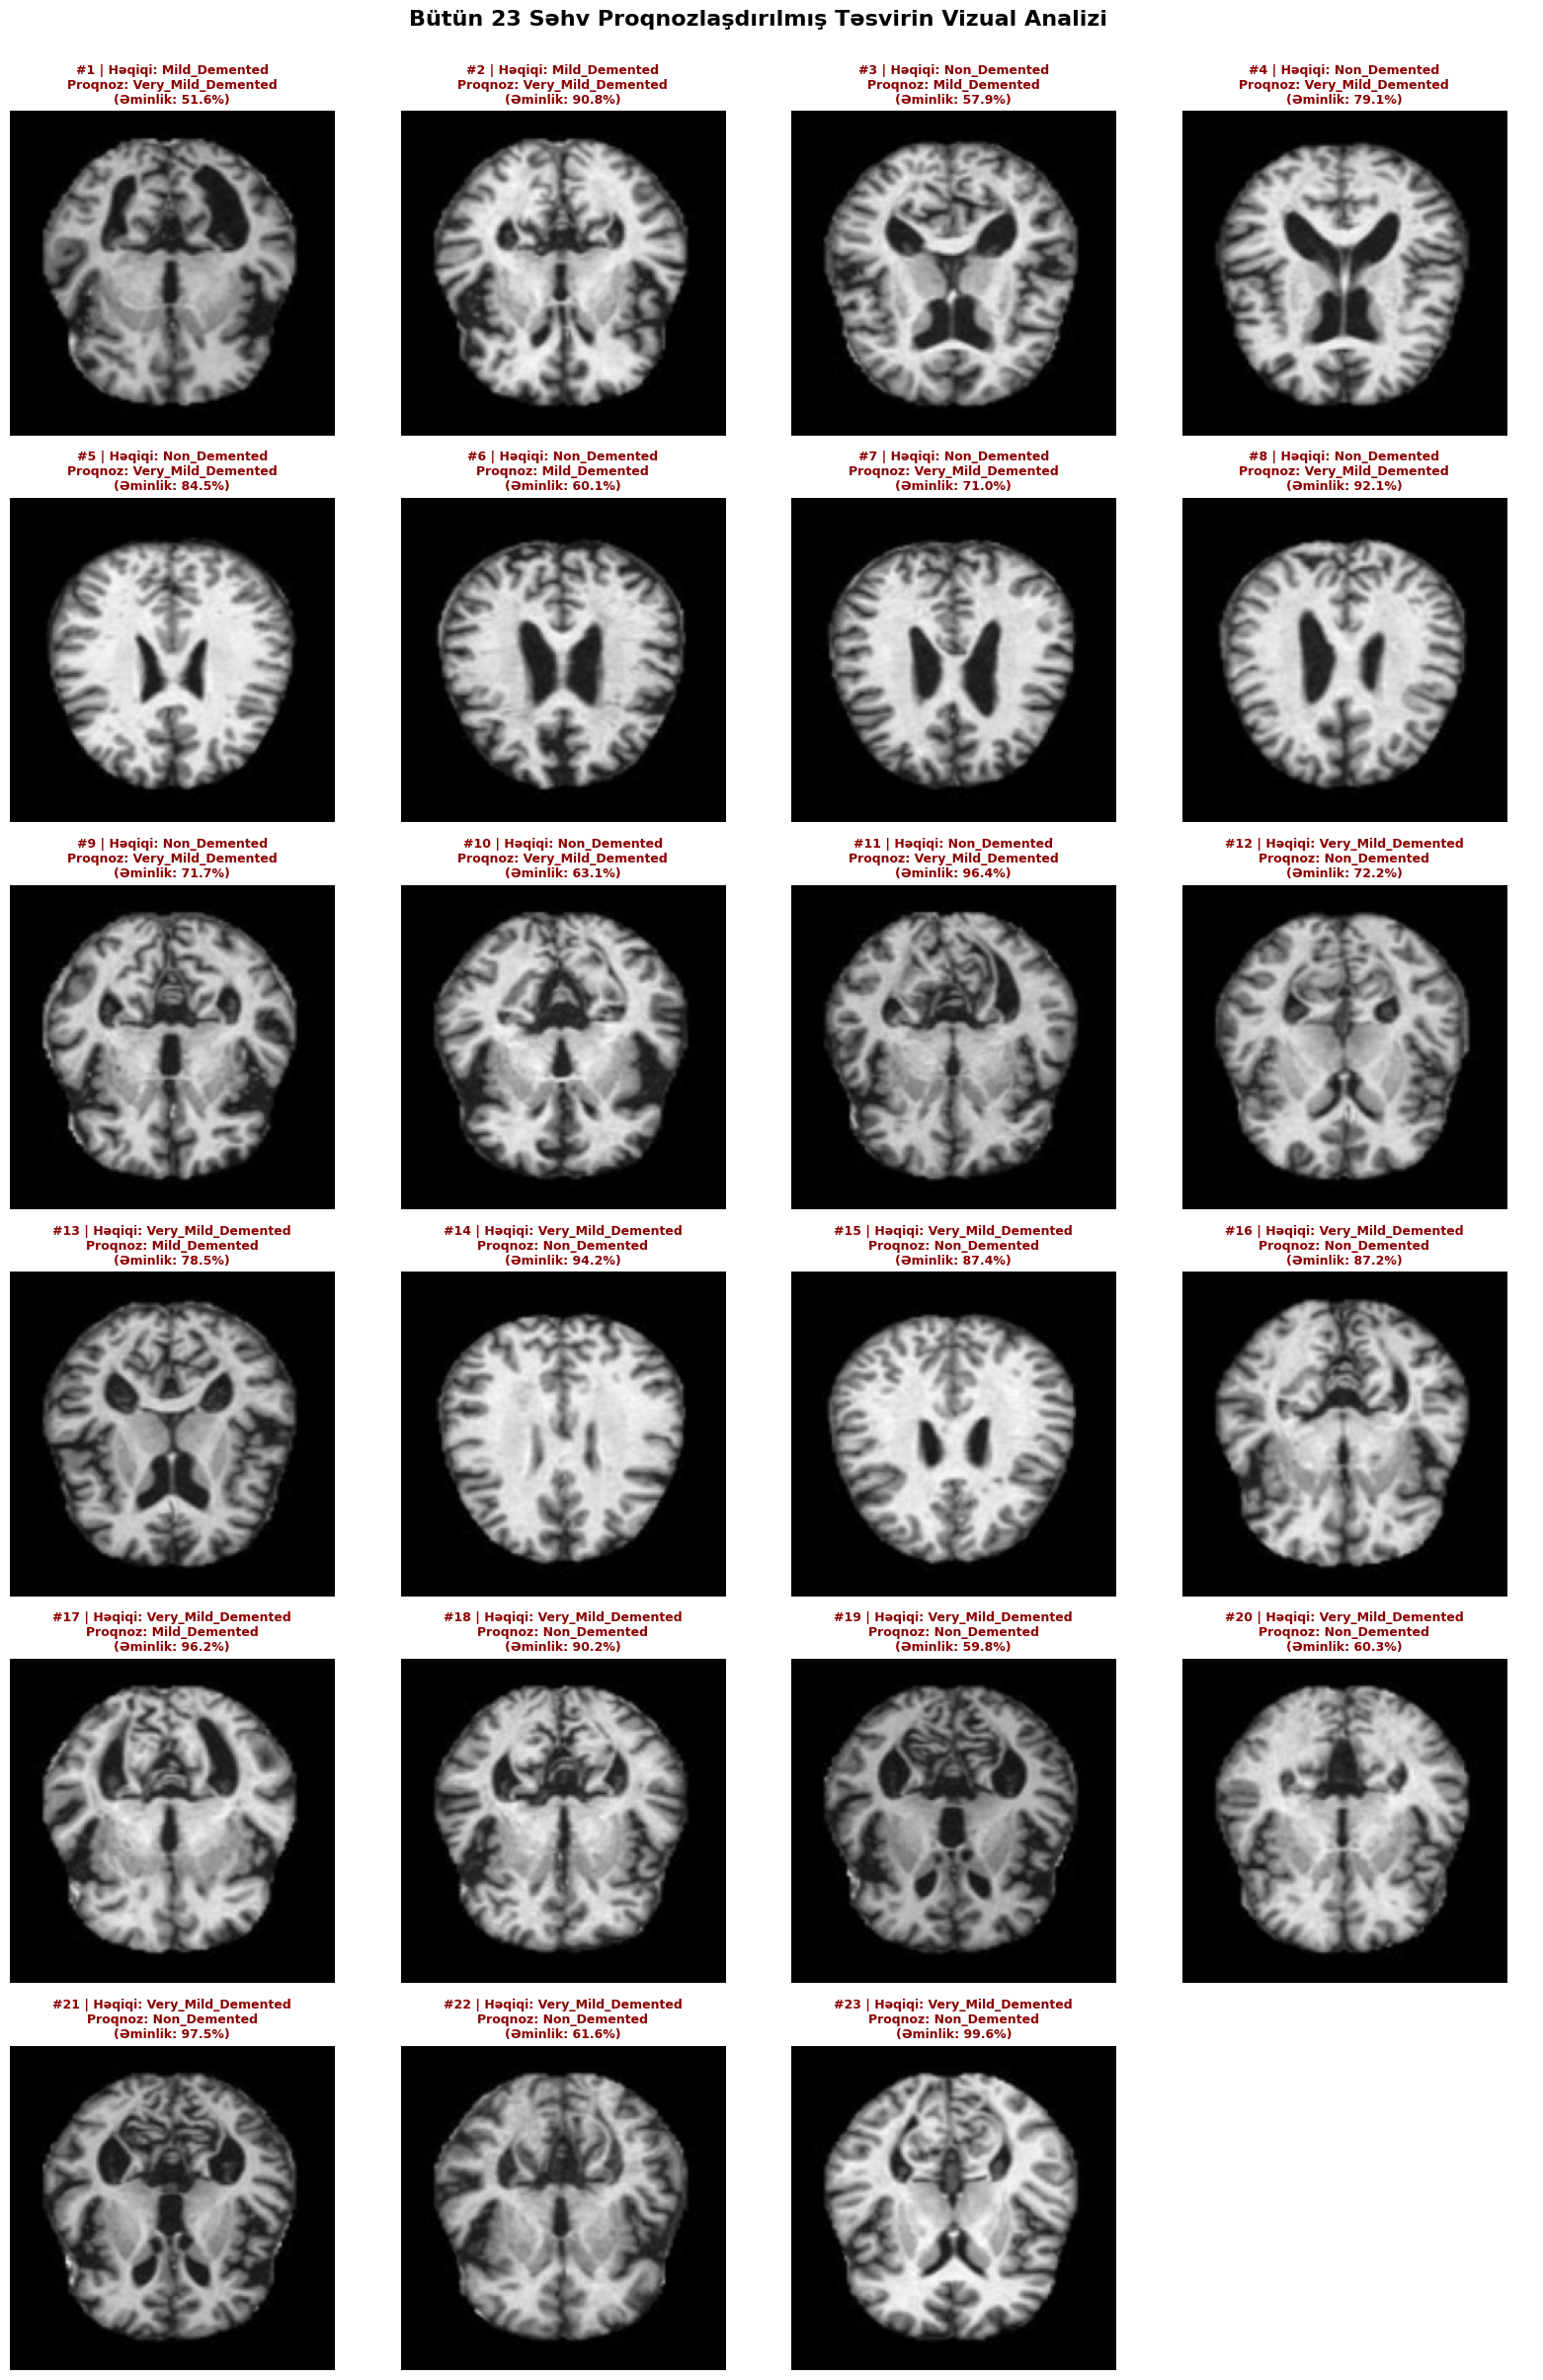


✓ Yüksək keyfiyyətli şəkil Google Drive-a saxlanıldı: /content/drive/MyDrive/alzheimer_error_analysis_grid.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.models import convnext_small
from google.colab import drive, files
import matplotlib.pyplot as plt
import numpy as np
import shutil

# 1. Google Drive-ın Qoşulması və Device Quraşdırılması
drive.mount('/content/drive')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Test Dataset-inin Yoxlanılması və Unzip Olunması
if not os.path.exists('/content/test'):
    print("--> Test dataset-i Colab diskində tapılmadı. Unzip olunur...")
    !unzip -q /content/dataset.zip -d /content/
    print("✓ Dataset qovluqları hazırlandı.")

# 3. Test Loader-in Qurulması
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

test_dataset = datasets.ImageFolder(root='/content/test/test', transform=val_test_transforms)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)
class_names = list(test_dataset.class_to_idx.keys())

# 4. ConvNeXt-Small Modelinin və Drive-dakı Çəkilərin Yüklənməsi
model_v2 = convnext_small(weights=None)
num_features = model_v2.classifier[2].in_features
model_v2.classifier[2] = nn.Linear(num_features, 3)

checkpoint_path = '/content/drive/MyDrive/Alzheimer_Model_Checkpoints/alzheimer_convnext_best.pth'
checkpoint = torch.load(checkpoint_path, map_location=device)
model_v2.load_state_dict(checkpoint['state_dict'])
model_v2 = model_v2.to(device)
model_v2.eval()

print(f"✓ Model Drive-dan uğurla yükləndi! (Val Acc: {checkpoint['best_acc']:.2f}%)\n")

# 5. Səhv Proqnozlaşdırılan BÜTÜN Şəkillərin Tapılması
misclassified = []

with torch.no_grad():
    for images, labels in test_loader:
        images_gpu = images.to(device)
        outputs = model_v2(images_gpu)
        probabilities = F.softmax(outputs, dim=1)
        probs, preds = torch.max(probabilities, 1)

        for i in range(len(labels)):
            if preds[i] != labels[i]:
                misclassified.append({
                    'image': images[i],
                    'true_label': labels[i].item(),
                    'pred_label': preds[i].item(),
                    'confidence': probs[i].item() * 100
                })

num_errors = len(misclassified)
print(f"Ümumi test şəkilləri üzrə xəta sayısı: {num_errors} / {len(test_dataset)}")

# Denormalizasiya funksiyası
def denormalize(tensor, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]):
    tensor = tensor.clone()
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m)
    return torch.clamp(tensor, 0, 1)

# 6. BÜTÜN SƏHV OLUNMUŞ ŞƏKİLLƏRİN VİZUALİZASİYASI VƏ DOĞRU ŞƏKİLDƏ SAXLANILMASI
if num_errors == 0:
    print("\nMükəmməl! Test setində heç bir səhv tapılmadı.")
else:
    cols = 4
    rows = math.ceil(num_errors / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    axes = axes.flatten()

    for idx in range(num_errors):
        item = misclassified[idx]
        img = denormalize(item['image']).permute(1, 2, 0).numpy()

        true_str = class_names[item['true_label']]
        pred_str = class_names[item['pred_label']]
        conf_str = f"{item['confidence']:.1f}%"

        axes[idx].imshow(img)
        axes[idx].set_title(
            f"#{idx+1} | Həqiqi: {true_str}\nProqnoz: {pred_str}\n(Əminlik: {conf_str})",
            color='darkred',
            fontsize=9,
            fontweight='bold'
        )
        axes[idx].axis('off')

    # Artıq qalan boş qrafik xanalarını gizlədirik
    for idx in range(num_errors, len(axes)):
        axes[idx].axis('off')

    plt.suptitle(
        f"Bütün {num_errors} Səhv Proqnozlaşdırılmış Təsvirin Vizual Analizi",
        fontsize=16,
        fontweight='bold',
        y=1.002
    )
    plt.tight_layout()

    # 1. Öncə şəkli fayla yazırıq (boş çıxmaması üçün plt.show()-dan ƏVVƏL)
    output_filename = "alzheimer_error_analysis_grid.png"
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')

    # 2. İndi ekranda göstəririk
    plt.show()

    # 3. Google Drive-a nüsxəsini kopyalayırıq (Paylaşmaq üçün)
    drive_save_path = "/content/drive/MyDrive/alzheimer_error_analysis_grid.png"
    shutil.copy(output_filename, drive_save_path)
    print(f"\n✓ Yüksək keyfiyyətli şəkil Google Drive-a saxlanıldı: {drive_save_path}")

    # 4. Avtomatik kompüterə yükləmə
    files.download(output_filename)

#Üçüncü Versiya

In [ ]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torchvision.models import convnext_small
from google.colab import drive
import numpy as np

drive.mount('/content/drive')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 1. WEIGHTED FOCAL LOSS KLASSI ---
class WeightedFocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        super(WeightedFocalLoss, self).__init__()
        self.alpha = alpha  # Tensor of weights per class
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss

        if self.alpha is not None:
            alpha_t = self.alpha.to(inputs.device)[targets]
            focal_loss = alpha_t * focal_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss

# --- 2. DATA TRANSFORMS ---
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

raw_train = datasets.ImageFolder('/content/train/train', transform=train_transform)
raw_val = datasets.ImageFolder('/content/val/val', transform=val_transform)

print("✓ Weighted Focal Loss və əsas mühit hazırlandı.")

Mounted at /content/drive
✓ Weighted Focal Loss və əsas mühit hazırlandı.


In [ ]:
class Stage1Dataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        img, orig_label = self.base_dataset[idx]
        # Non_Demented (1) -> 0 (Healthy)
        # Mild (0) & Very_Mild (2) -> 1 (Demented)
        binary_label = 0 if orig_label == 1 else 1
        return img, binary_label

train_loader_s1 = DataLoader(Stage1Dataset(raw_train), batch_size=32, shuffle=True, num_workers=2)
val_loader_s1 = DataLoader(Stage1Dataset(raw_val), batch_size=32, shuffle=False, num_workers=2)

model_s1 = convnext_small(weights='DEFAULT')
model_s1.classifier[2] = nn.Linear(model_s1.classifier[2].in_features, 2)
model_s1 = model_s1.to(device)

criterion_s1 = WeightedFocalLoss(gamma=2.0) # Stage 1 tam balanslı olduğu üçün alpha lazımsızdır
optimizer_s1 = torch.optim.AdamW(model_s1.parameters(), lr=1e-4, weight_decay=1e-2)
scheduler_s1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_s1, T_max=10)

best_acc_s1 = 0.0
save_path_s1 = '/content/drive/MyDrive/Alzheimer_Model_Checkpoints/alzheimer_stage1_binary_best.pth'

print("="*60)
print("     STAGE 1 (HEALTHY vs DEMENTED) TƏLİMİ BAŞLAYIR")
print("="*60)

for epoch in range(1, 11):
    model_s1.train()
    train_correct, total_train = 0, 0
    for imgs, labels in train_loader_s1:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer_s1.zero_grad()
        outputs = model_s1(imgs)
        loss = criterion_s1(outputs, labels)
        loss.backward()
        optimizer_s1.step()

        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)
        total_train += labels.size(0)

    scheduler_s1.step()

    model_s1.eval()
    val_correct, total_val = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader_s1:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model_s1(imgs)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)
            total_val += labels.size(0)

    train_acc = (train_correct.double() / total_train) * 100
    val_acc = (val_correct.double() / total_val) * 100
    print(f"Epoch [{epoch:02d}/10] | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")

    if val_acc > best_acc_s1:
        best_acc_s1 = val_acc
        torch.save({'state_dict': model_s1.state_dict(), 'best_acc': best_acc_s1}, save_path_s1)
        print(f"  └─ Stage 1 Checkpoint saxlanıldı ({best_acc_s1:.2f}%)")

Downloading: "https://download.pytorch.org/models/convnext_small-0c510722.pth" to /root/.cache/torch/hub/checkpoints/convnext_small-0c510722.pth


100%|██████████| 192M/192M [00:01<00:00, 129MB/s] 


     STAGE 1 (HEALTHY vs DEMENTED) TƏLİMİ BAŞLAYIR
Epoch [01/10] | Train Acc: 58.38% | Val Acc: 69.68%
  └─ Stage 1 Checkpoint saxlanıldı (69.68%)
Epoch [02/10] | Train Acc: 66.25% | Val Acc: 70.21%
  └─ Stage 1 Checkpoint saxlanıldı (70.21%)
Epoch [03/10] | Train Acc: 72.51% | Val Acc: 75.89%
  └─ Stage 1 Checkpoint saxlanıldı (75.89%)
Epoch [04/10] | Train Acc: 78.20% | Val Acc: 76.21%
  └─ Stage 1 Checkpoint saxlanıldı (76.21%)
Epoch [05/10] | Train Acc: 84.51% | Val Acc: 83.68%
  └─ Stage 1 Checkpoint saxlanıldı (83.68%)
Epoch [06/10] | Train Acc: 90.10% | Val Acc: 94.74%
  └─ Stage 1 Checkpoint saxlanıldı (94.74%)
Epoch [07/10] | Train Acc: 94.16% | Val Acc: 92.11%
Epoch [08/10] | Train Acc: 96.53% | Val Acc: 96.11%
  └─ Stage 1 Checkpoint saxlanıldı (96.11%)
Epoch [09/10] | Train Acc: 97.72% | Val Acc: 97.47%
  └─ Stage 1 Checkpoint saxlanıldı (97.47%)
Epoch [10/10] | Train Acc: 98.62% | Val Acc: 98.00%
  └─ Stage 1 Checkpoint saxlanıldı (98.00%)


In [ ]:
def get_demented_indices(dataset):
    return [idx for idx, (_, label) in enumerate(dataset) if label in [0, 2]]

class Stage2Dataset(Dataset):
    def __init__(self, base_dataset, indices):
        self.base_dataset = base_dataset
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        img, orig_label = self.base_dataset[real_idx]
        # Mild_Demented (0) -> 0, Very_Mild_Demented (2) -> 1
        binary_label = 0 if orig_label == 0 else 1
        return img, binary_label

train_s2_ds = Stage2Dataset(raw_train, get_demented_indices(raw_train))
val_s2_ds = Stage2Dataset(raw_val, get_demented_indices(raw_val))

train_loader_s2 = DataLoader(train_s2_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader_s2 = DataLoader(val_s2_ds, batch_size=32, shuffle=False, num_workers=2)

# CLASS WEIGHTS (Mild=1.750, Very_Mild=0.700)
stage2_weights = torch.tensor([1.750, 0.700]).to(device)
criterion_s2 = WeightedFocalLoss(alpha=stage2_weights, gamma=2.0)

model_s2 = convnext_small(weights='DEFAULT')
model_s2.classifier[2] = nn.Linear(model_s2.classifier[2].in_features, 2)
model_s2 = model_s2.to(device)

optimizer_s2 = torch.optim.AdamW(model_s2.parameters(), lr=1e-4, weight_decay=1e-2)
scheduler_s2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_s2, T_max=10)

best_acc_s2 = 0.0
save_path_s2 = '/content/drive/MyDrive/Alzheimer_Model_Checkpoints/alzheimer_stage2_binary_best.pth'

print("="*75)
print("  STAGE 2 (MILD vs VERY_MILD) WEIGHTED FOCAL LOSS TƏLİMİ (LOSS İZLƏMƏ İLƏ)")
print("="*75)

for epoch in range(1, 11):
    # --- TRAINING PHASE ---
    model_s2.train()
    train_loss, train_correct, total_train = 0.0, 0, 0
    for imgs, labels in train_loader_s2:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer_s2.zero_grad()
        outputs = model_s2(imgs)
        loss = criterion_s2(outputs, labels)
        loss.backward()
        optimizer_s2.step()

        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)
        total_train += labels.size(0)

    scheduler_s2.step()

    # --- VALIDATION PHASE ---
    model_s2.eval()
    val_loss, val_correct, total_val = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader_s2:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model_s2(imgs)
            loss = criterion_s2(outputs, labels)

            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)
            total_val += labels.size(0)

    # Ortalamaların Hesablanması
    train_loss_avg = train_loss / total_train
    val_loss_avg = val_loss / total_val
    train_acc = (train_correct.double() / total_train) * 100
    val_acc = (val_correct.double() / total_val) * 100

    print(f"Epoch [{epoch:02d}/10] | Train Loss: {train_loss_avg:.4f} | Train Acc: {train_acc:.2f}% | Val Loss: {val_loss_avg:.4f} | Val Acc: {val_acc:.2f}%")

    if val_acc > best_acc_s2:
        best_acc_s2 = val_acc
        torch.save({'state_dict': model_s2.state_dict(), 'best_acc': best_acc_s2}, save_path_s2)
        print(f"  └─ Stage 2 Checkpoint saxlanıldı (Val Acc: {best_acc_s2:.2f}%)")

print("\n✓ STAGE 2 Təlimi Uğurla Tamamlandı!")

  STAGE 2 (MILD vs VERY_MILD) WEIGHTED FOCAL LOSS TƏLİMİ (LOSS İZLƏMƏ İLƏ)
Epoch [01/10] | Train Loss: 0.1967 | Train Acc: 49.34% | Val Loss: 0.1725 | Val Acc: 28.51%
  └─ Stage 2 Checkpoint saxlanıldı (Val Acc: 28.51%)
Epoch [02/10] | Train Loss: 0.1740 | Train Acc: 53.17% | Val Loss: 0.1601 | Val Acc: 68.72%
  └─ Stage 2 Checkpoint saxlanıldı (Val Acc: 68.72%)
Epoch [03/10] | Train Loss: 0.1587 | Train Acc: 64.51% | Val Loss: 0.1541 | Val Acc: 75.74%
  └─ Stage 2 Checkpoint saxlanıldı (Val Acc: 75.74%)
Epoch [04/10] | Train Loss: 0.1411 | Train Acc: 69.70% | Val Loss: 0.1717 | Val Acc: 50.00%
Epoch [05/10] | Train Loss: 0.1271 | Train Acc: 75.67% | Val Loss: 0.1538 | Val Acc: 50.85%
Epoch [06/10] | Train Loss: 0.0863 | Train Acc: 86.38% | Val Loss: 0.0673 | Val Acc: 88.51%
  └─ Stage 2 Checkpoint saxlanıldı (Val Acc: 88.51%)
Epoch [07/10] | Train Loss: 0.0536 | Train Acc: 91.62% | Val Loss: 0.0509 | Val Acc: 93.19%
  └─ Stage 2 Checkpoint saxlanıldı (Val Acc: 93.19%)
Epoch [08/10] | 


  TWO-STEP WEIGHTED FOCAL PIPELINE - YEKUN TEST HESABATI
                    precision    recall  f1-score   support

     Mild_Demented     0.9333    0.9333    0.9333       135
      Non_Demented     0.9812    0.9792    0.9802       480
Very_Mild_Demented     0.9525    0.9554    0.9539       336

          accuracy                         0.9642       951
         macro avg     0.9557    0.9560    0.9558       951
      weighted avg     0.9643    0.9642    0.9643       951



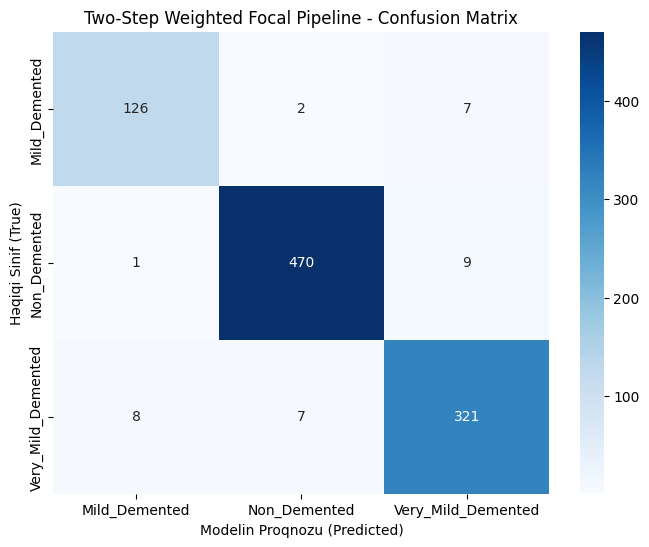

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Hər İki Modelin Yüklənməsi
checkpoint_s1 = torch.load(save_path_s1, map_location=device)
model_s1.load_state_dict(checkpoint_s1['state_dict'])
model_s1.eval()

checkpoint_s2 = torch.load(save_path_s2, map_location=device)
model_s2.load_state_dict(checkpoint_s2['state_dict'])
model_s2.eval()

# 2. Test Dataset Və Loader
raw_test = datasets.ImageFolder('/content/test/test', transform=val_transform)
test_loader_final = DataLoader(raw_test, batch_size=32, shuffle=False, num_workers=2)
class_names = list(raw_test.class_to_idx.keys())

all_preds, all_labels = [], []

# 3. Two-Step Pipeline Məntiqilə Proqnozlaşdırma
with torch.no_grad():
    for imgs, labels in test_loader_final:
        imgs = imgs.to(device)

        # Step 1: Stage 1 Model (Healthy vs Demented)
        out_s1 = model_s1(imgs)
        _, preds_s1 = torch.max(out_s1, 1)

        # Step 2: Stage 2 Model (Mild vs Very Mild)
        out_s2 = model_s2(imgs)
        _, preds_s2 = torch.max(out_s2, 1)

        for i in range(len(labels)):
            if preds_s1[i] == 0:
                final_pred = 1  # Non_Demented index
            else:
                final_pred = 0 if preds_s2[i] == 0 else 2  # Mild=0, Very_Mild=2

            all_preds.append(final_pred)
            all_labels.append(labels[i].item())

# 4. Yekun Hesabatın və Confusion Matrix-in Çapı
print("\n" + "="*65)
print("  TWO-STEP WEIGHTED FOCAL PIPELINE - YEKUN TEST HESABATI")
print("="*65)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Modelin Proqnozu (Predicted)')
plt.ylabel('Həqiqi Sinif (True)')
plt.title('Two-Step Weighted Focal Pipeline - Confusion Matrix')
plt.show()

#Dördüncü Versiya

In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

# ==========================================
# 1. RANDOM SEED SABİTLƏNMƏSİ (seed = 42)
# ==========================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"İstifadə olunan cihaz: {device}")

# ==========================================
# 2. QOVLUQ YOLLARININ AVTOMATİK TƏYİNİ
# ==========================================
if os.path.exists('/content/train/train'):
    train_dir = '/content/train/train'
elif os.path.exists('/content/train'):
    train_dir = '/content/train'
else:
    raise FileNotFoundError("Train qovluğu tapılmadı!")

if os.path.exists('/content/test/test'):
    val_dir = '/content/test/test'
elif os.path.exists('/content/val/val'):
    val_dir = '/content/val/val'
elif os.path.exists('/content/test'):
    val_dir = '/content/test'
else:
    raise FileNotFoundError("Validation/Test qovluğu tapılmadı!")

print(f"Train Yolu: {train_dir}")
print(f"Val Yolu:   {val_dir}")

# ==========================================
# 3. DATA AUGMENTATION VƏ LOADER-LƏR
# ==========================================
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset = datasets.ImageFolder(val_dir, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

class_names = train_dataset.classes
print(f"\nDüzgün Tapılan Siniflər ({len(class_names)} sinif): {class_names}")

# Sanity Check (Yoxlama)
if len(class_names) < 3:
    raise ValueError(f"Xəta! Cəmi {len(class_names)} sinif tapıldı: {class_names}. Qovluq yollarını yoxlayın!")

# ==========================================
# 4. 3-CLASS WEIGHTED FOCAL LOSS
# ==========================================
class WeightedFocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super(WeightedFocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss

        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            focal_loss = alpha_t * focal_loss

        return focal_loss.mean()

# Sinif çəkiləri (0: Mild_Demented, 1: Non_Demented, 2: Very_Mild_Demented)
class_weights = torch.tensor([1.8, 0.7, 1.2]).to(device)
criterion = WeightedFocalLoss(alpha=class_weights, gamma=2.0)

# ==========================================
# 5. CONVNEXT-SMALL MODELİ VƏ OPTIMIZER
# ==========================================
model = models.convnext_small(weights=models.ConvNeXt_Small_Weights.DEFAULT)
model.classifier[2] = nn.Linear(model.classifier[2].in_features, 3)
model = model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

# ==========================================
# 6. TƏLİM PROSESİ (10 EPOCH)
# ==========================================
epochs = 10
best_val_acc = 0.0
save_path = "/content/convnext_single_best.pth"

print("\n" + "="*65)
print("  TƏK CONVNEXT-SMALL (3-CLASS WEIGHTED FOCAL LOSS) TƏLİMİ İŞƏ DÜŞDÜ")
print("="*65)

for epoch in range(epochs):
    # Train
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)
        train_total += imgs.size(0)

    scheduler.step()
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = (train_correct.double() / train_total) * 100

    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)
            val_total += imgs.size(0)

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct.double() / val_total) * 100

    print(f"Epoch [{epoch+1:02d}/{epochs:02d}] | "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%")

    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save({'state_dict': model.state_dict(), 'val_acc': best_val_acc}, save_path)
        print(f"  └─ YENİ BEST CHECKPOINT SAXLANILDI: {best_val_acc:.2f}%")

print("\n✓ Təlim Tamamlandı!")

İstifadə olunan cihaz: cuda
Train Yolu: /content/train/train
Val Yolu:   /content/test/test

Düzgün Tapılan Siniflər (3 sinif): ['Mild_Demented', 'Non_Demented', 'Very_Mild_Demented']

  TƏK CONVNEXT-SMALL (3-CLASS WEIGHTED FOCAL LOSS) TƏLİMİ İŞƏ DÜŞDÜ
Epoch [01/10] | Train Loss: 0.4665 | Train Acc: 45.89% | Val Loss: 0.4015 | Val Acc: 50.16%
  └─ YENİ BEST CHECKPOINT SAXLANILDI: 50.16%
Epoch [02/10] | Train Loss: 0.3795 | Train Acc: 56.28% | Val Loss: 0.3919 | Val Acc: 58.46%
  └─ YENİ BEST CHECKPOINT SAXLANILDI: 58.46%
Epoch [03/10] | Train Loss: 0.3058 | Train Acc: 62.80% | Val Loss: 0.2858 | Val Acc: 63.41%
  └─ YENİ BEST CHECKPOINT SAXLANILDI: 63.41%
Epoch [04/10] | Train Loss: 0.2242 | Train Acc: 72.36% | Val Loss: 0.3705 | Val Acc: 48.79%
Epoch [05/10] | Train Loss: 0.1694 | Train Acc: 79.48% | Val Loss: 0.1410 | Val Acc: 80.65%
  └─ YENİ BEST CHECKPOINT SAXLANILDI: 80.65%
Epoch [06/10] | Train Loss: 0.0959 | Train Acc: 87.46% | Val Loss: 0.0910 | Val Acc: 85.59%
  └─ YENİ BEST 


  TƏK CONVNEXT-SMALL MODELİ - YEKUN TEST HESABATI
                    precision    recall  f1-score   support

     Mild_Demented     0.9441    1.0000    0.9712       135
      Non_Demented     0.9641    0.9521    0.9581       480
Very_Mild_Demented     0.9341    0.9286    0.9313       336

          accuracy                         0.9506       951
         macro avg     0.9474    0.9602    0.9535       951
      weighted avg     0.9507    0.9506    0.9505       951



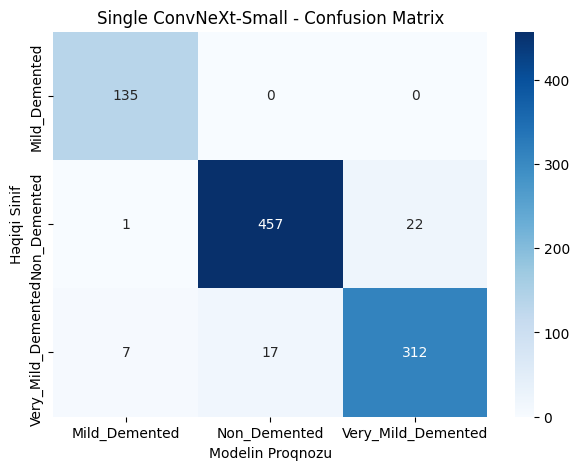

In [ ]:
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Modelin Yüklənməsi
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_dir = '/content/test/test' if os.path.exists('/content/test/test') else '/content/test'
val_dataset = datasets.ImageFolder(val_dir, transform=val_transform)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

model_conv = models.convnext_small(weights=None)
model_conv.classifier[2] = torch.nn.Linear(model_conv.classifier[2].in_features, 3)

checkpoint = torch.load("/content/convnext_single_best.pth", map_location=device)
model_conv.load_state_dict(checkpoint['state_dict'])
model_conv = model_conv.to(device)
model_conv.eval()

# 2. Test Təhlili
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        outputs = model_conv(imgs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = val_dataset.classes

print("\n" + "="*65)
print("  TƏK CONVNEXT-SMALL MODELİ - YEKUN TEST HESABATI")
print("="*65)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Modelin Proqnozu')
plt.ylabel('Həqiqi Sinif')
plt.title('Single ConvNeXt-Small - Confusion Matrix')
plt.show()

Downloading: "https://download.pytorch.org/models/swin_s-5e29d889.pth" to /root/.cache/torch/hub/checkpoints/swin_s-5e29d889.pth


100%|██████████| 190M/190M [00:01<00:00, 108MB/s]



  1/2: SWIN TRANSFORMER (SWIN-S) TƏLİMİ İŞƏ DÜŞDÜ
Epoch [01/10] | Train Acc: 43.29% | Val Loss: 0.4307 | Val Acc: 45.11%
Epoch [02/10] | Train Acc: 50.82% | Val Loss: 0.3805 | Val Acc: 53.52%
Epoch [03/10] | Train Acc: 55.49% | Val Loss: 0.3576 | Val Acc: 54.99%
Epoch [04/10] | Train Acc: 55.58% | Val Loss: 0.3327 | Val Acc: 57.31%
Epoch [05/10] | Train Acc: 59.48% | Val Loss: 0.2914 | Val Acc: 61.20%
Epoch [06/10] | Train Acc: 63.59% | Val Loss: 0.2932 | Val Acc: 62.57%
Epoch [07/10] | Train Acc: 69.58% | Val Loss: 0.2147 | Val Acc: 66.98%
Epoch [08/10] | Train Acc: 73.64% | Val Loss: 0.1838 | Val Acc: 69.30%
Epoch [09/10] | Train Acc: 77.36% | Val Loss: 0.1600 | Val Acc: 74.97%
Epoch [10/10] | Train Acc: 79.39% | Val Loss: 0.1559 | Val Acc: 77.29%

✓ Swin Transformer Təlimi Btdi!

  2/2: VOTING ENSEMBLE (CONVNEXT + SWIN TRANSFORMER) TESTİ

  ENSEMBLE (CONVNEXT + SWIN) - YEKUN TEST HESABATI
                    precision    recall  f1-score   support

     Mild_Demented     0.9708    

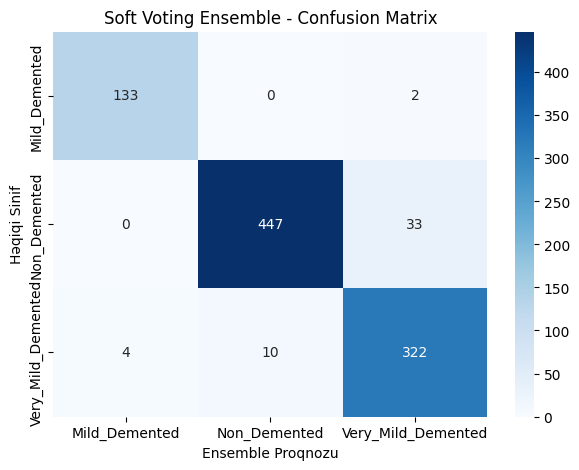

In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. SEED SABİTLƏNMƏSİ
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. DATA LOADER-LƏR
train_dir = '/content/train/train' if os.path.exists('/content/train/train') else '/content/train'
val_dir = '/content/test/test' if os.path.exists('/content/test/test') else '/content/test'

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset = datasets.ImageFolder(val_dir, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

class_names = train_dataset.classes

# 3. FOCAL LOSS
class WeightedFocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super(WeightedFocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        if self.alpha is not None:
            focal_loss = self.alpha[targets] * focal_loss
        return focal_loss.mean()

class_weights = torch.tensor([1.8, 0.7, 1.2]).to(device)
criterion = WeightedFocalLoss(alpha=class_weights, gamma=2.0)

# 4. SWIN TRANSFORMER MODELİ
model_swin = models.swin_s(weights=models.Swin_S_Weights.DEFAULT)
model_swin.head = nn.Linear(model_swin.head.in_features, 3)
model_swin = model_swin.to(device)

optimizer_swin = torch.optim.AdamW(model_swin.parameters(), lr=1e-4, weight_decay=1e-2)
scheduler_swin = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_swin, T_max=10)

save_path_swin = "/content/swin_single_best.pth"
best_val_acc_swin = 0.0

print("\n" + "="*65)
print("  1/2: SWIN TRANSFORMER (SWIN-S) TƏLİMİ İŞƏ DÜŞDÜ")
print("="*65)

for epoch in range(10):
    model_swin.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer_swin.zero_grad()
        outputs = model_swin(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_swin.step()

        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)
        train_total += imgs.size(0)

    scheduler_swin.step()

    model_swin.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model_swin(imgs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)
            val_total += imgs.size(0)

    val_acc = (val_correct.double() / val_total) * 100
    print(f"Epoch [{epoch+1:02d}/10] | Train Acc: {(train_correct.double()/train_total)*100:.2f}% | Val Loss: {val_loss/val_total:.4f} | Val Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc_swin:
        best_val_acc_swin = val_acc
        torch.save({'state_dict': model_swin.state_dict()}, save_path_swin)

print("\n✓ Swin Transformer Təlimi Btdi!")

# ==========================================
# 5. CONVNEXT + SWIN ENSEMBLE (SOFT VOTING)
# ==========================================
print("\n" + "="*65)
print("  2/2: VOTING ENSEMBLE (CONVNEXT + SWIN TRANSFORMER) TESTİ")
print("="*65)

# Load ConvNeXt
model_conv = models.convnext_small(weights=None)
model_conv.classifier[2] = nn.Linear(model_conv.classifier[2].in_features, 3)
checkpoint_conv = torch.load("/content/convnext_single_best.pth", map_location=device)
model_conv.load_state_dict(checkpoint_conv['state_dict'])
model_conv = model_conv.to(device).eval()

# Load Swin
checkpoint_swin = torch.load(save_path_swin, map_location=device)
model_swin.load_state_dict(checkpoint_swin['state_dict'])
model_swin = model_swin.to(device).eval()

all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)

        # Logits
        out_conv = model_conv(imgs)
        out_swin = model_swin(imgs)

        # Softmax ilə Ehtimallara Çevrilmə
        prob_conv = F.softmax(out_conv, dim=1)
        prob_swin = F.softmax(out_swin, dim=1)

        # Soft Voting (Ehtimalların Ortalaması)
        ensemble_prob = (prob_conv + prob_swin) / 2.0
        _, preds = torch.max(ensemble_prob, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("\n" + "="*65)
print("  ENSEMBLE (CONVNEXT + SWIN) - YEKUN TEST HESABATI")
print("="*65)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Ensemble Proqnozu')
plt.ylabel('Həqiqi Sinif')
plt.title('Soft Voting Ensemble - Confusion Matrix')
plt.show()


  AĞIRLIKLI ENSEMBLE (0.8 ConvNeXt + 0.2 Swin) HESABATI
                    precision    recall  f1-score   support

     Mild_Demented     0.9507    1.0000    0.9747       135
      Non_Demented     0.9700    0.9437    0.9567       480
Very_Mild_Demented     0.9240    0.9405    0.9322       336

          accuracy                         0.9506       951
         macro avg     0.9482    0.9614    0.9545       951
      weighted avg     0.9510    0.9506    0.9506       951



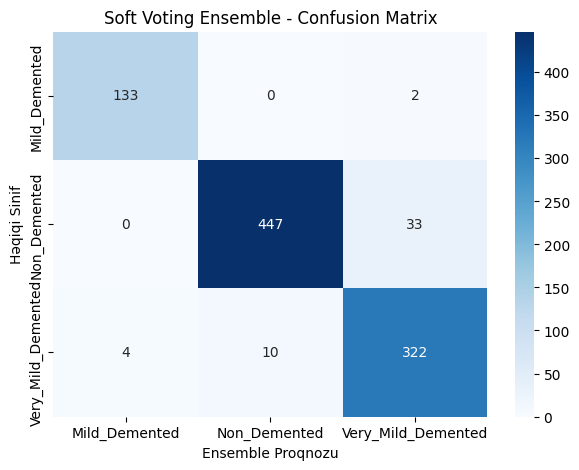

In [ ]:
# AĞIRLIKLI SOFT VOTING (ConvNeXt %80, Swin %20)
model_conv.eval()
model_swin.eval()

all_preds_weighted, all_labels_weighted = [], []

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)

        out_conv = model_conv(imgs)
        out_swin = model_swin(imgs)

        prob_conv = F.softmax(out_conv, dim=1)
        prob_swin = F.softmax(out_swin, dim=1)

        # ConvNeXt modeline 0.8, Swin modeline 0.2 ağırlık veriyoruz:
        weighted_prob = (0.8 * prob_conv) + (0.2 * prob_swin)
        _, preds = torch.max(weighted_prob, 1)

        all_preds_weighted.extend(preds.cpu().numpy())
        all_labels_weighted.extend(labels.numpy())

print("\n" + "="*65)
print("  AĞIRLIKLI ENSEMBLE (0.8 ConvNeXt + 0.2 Swin) HESABATI")
print("="*65)
print(classification_report(all_labels_weighted, all_preds_weighted, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Ensemble Proqnozu')
plt.ylabel('Həqiqi Sinif')
plt.title('Soft Voting Ensemble - Confusion Matrix')
plt.show()

In [ ]:
from google.colab import drive
import shutil
import os

# Drive-ı qoşuruq
drive.mount('/content/drive')

# Qovluq yaradırıq
drive_path = "/content/drive/MyDrive/Alzheimer_Ensemble_Models"
os.makedirs(drive_path, exist_ok=True)

# Çəkiləri kopyalayırıq
shutil.copy("/content/convnext_single_best.pth", f"{drive_path}/convnext_best.pth")
shutil.copy("/content/swin_single_best.pth", f"{drive_path}/swin_best.pth")

print("✓ Hər iki model Google Drive-da təhlükəsiz saxlanıldı!")

Mounted at /content/drive
✓ Hər iki model Google Drive-da təhlükəsiz saxlanıldı!
